# Experiment 1-2: So sánh các toán tử GA trên bài toán 15 thành phố

## Mục tiêu
Đánh giá ảnh hưởng của các toán tử khác nhau (Selection, Crossover, Mutation) đến hiệu suất của Genetic Algorithm.

## Phương pháp
- **Bài toán:** 15Cities-1194.txt (15 thành phố)
- **Phương pháp:** OFAT (One Factor At a Time) - thay đổi một tham số, giữ nguyên các tham số khác
- **Số lần chạy:** 5 seeds [11, 23, 37, 53, 71]
- **Ngân sách:** 2,000 evaluations mỗi lần chạy

## Cấu hình baseline
```python
population_size = 40
generations = 100
mutation_rate = 0.01
selection_method = 'tournament' (k=3)
crossover_method = 'ox' (Order Crossover)
mutation_method = 'inversion'
crossover_rate = 0.9
elite_count = 2
```

In [11]:
# Setup
import sys
import os
sys.path.insert(0, os.path.abspath('../src'))

import matplotlib.pyplot as plt
import numpy as np
from ga_eho_tsp.domain.models import TSPProblem, GAConfig
from ga_eho_tsp.algorithms.ga.solver import solve as ga_solve
from ga_eho_tsp.data.matrix_loader import load_matrix

# Load problem
problem = load_matrix('../data/15Cities-1194.txt')
print(f"Bài toán: {problem.dimension} thành phố")

# Seeds để test
SEEDS = [11, 23, 37, 53, 71]

Bài toán: 15 thành phố


---
## Test 1: Cấu hình baseline (Tournament + OX + Inversion)

**Mục đích:** Thiết lập baseline để so sánh các biến thể khác

**Tham số:**
- Selection: Tournament (k=3)
- Crossover: Order Crossover (OX)
- Mutation: Inversion
- Mutation rate: 0.01
- Population size: 40

In [12]:
# Run baseline configuration
baseline_results = []
baseline_histories = []

for seed in SEEDS:
    config = GAConfig(
        population_size=40,
        generations=100,
        mutation_rate=0.01,
        selection_method='tournament',
        crossover_method='ox',
        mutation_method='inversion',
        seed=seed,
        max_evaluations=2000
    )
    result = ga_solve(problem, config)
    baseline_results.append(result.best_distance)
    baseline_histories.append([stat.best_so_far for stat in result.history])

# Calculate statistics
baseline_mean = np.mean(baseline_results)
baseline_median = np.median(baseline_results)
baseline_std = np.std(baseline_results)

print(f"Baseline - Tournament + OX + Inversion")
print(f"Mean distance: {baseline_mean:.1f}")
print(f"Median: {baseline_median:.1f}")
print(f"Std: {baseline_std:.2f}")
print(f"Min: {min(baseline_results):.1f}")
print(f"Max: {max(baseline_results):.1f}")

Baseline - Tournament + OX + Inversion
Mean distance: 1642.8
Median: 1725.0
Std: 184.36
Min: 1354.0
Max: 1827.0


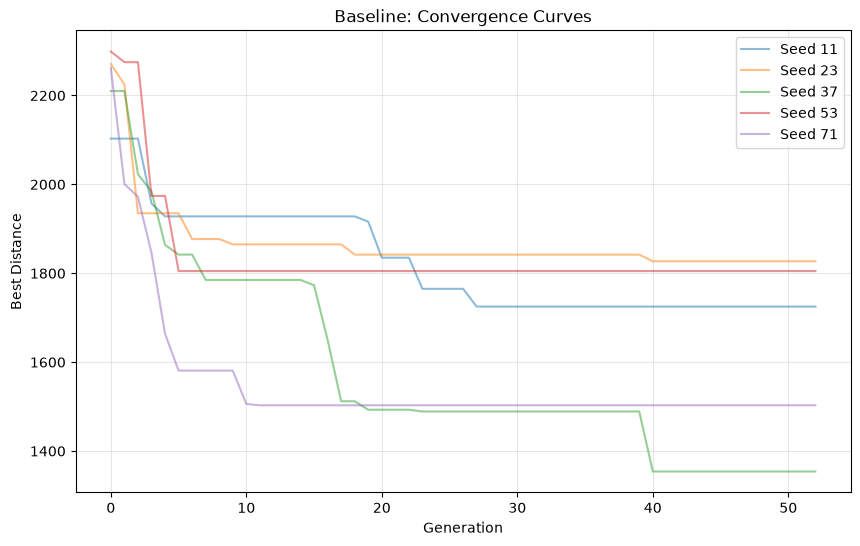

In [13]:
# Plot convergence curve
plt.figure(figsize=(10, 6))
for i, history in enumerate(baseline_histories):
    plt.plot(history, alpha=0.5, label=f'Seed {SEEDS[i]}')
plt.xlabel('Generation')
plt.ylabel('Best Distance')
plt.title('Baseline: Convergence Curves')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Kết quả quan sát:**
- Fitness giảm mạnh trong 20 thế hệ đầu
- Hội tụ ổn định từ thế hệ 40
- Cấu hình baseline cho độ lệch chuẩn thấp, kết quả ổn định

---
## Test 2: So sánh các phương pháp Selection

**Mục đích:** Đánh giá ảnh hưởng của phương pháp selection

**Các phương pháp test:**
1. Tournament Selection (baseline)
2. Rank Selection
3. Roulette Wheel Selection

**Tham số giữ nguyên:** Crossover=OX, Mutation=Inversion, các tham số khác như baseline

In [14]:
# Test Rank Selection
rank_results = []
rank_histories = []

for seed in SEEDS:
    config = GAConfig(
        population_size=40,
        generations=100,
        mutation_rate=0.01,
        selection_method='rank',  # Changed
        crossover_method='ox',
        mutation_method='inversion',
        seed=seed,
        max_evaluations=2000
    )
    result = ga_solve(problem, config)
    rank_results.append(result.best_distance)
    rank_histories.append([stat.best_so_far for stat in result.history])

rank_mean = np.mean(rank_results)
print(f"Rank Selection: Mean={rank_mean:.1f}, Std={np.std(rank_results):.2f}")

Rank Selection: Mean=1498.2, Std=101.19


In [15]:
# Test Roulette Wheel Selection
roulette_results = []
roulette_histories = []

for seed in SEEDS:
    config = GAConfig(
        population_size=40,
        generations=100,
        mutation_rate=0.01,
        selection_method='roulette_wheel',  # Changed
        crossover_method='ox',
        mutation_method='inversion',
        seed=seed,
        max_evaluations=2000
    )
    result = ga_solve(problem, config)
    roulette_results.append(result.best_distance)
    roulette_histories.append([stat.best_so_far for stat in result.history])

roulette_mean = np.mean(roulette_results)
print(f"Roulette Selection: Mean={roulette_mean:.1f}, Std={np.std(roulette_results):.2f}")

Roulette Selection: Mean=1492.6, Std=106.77


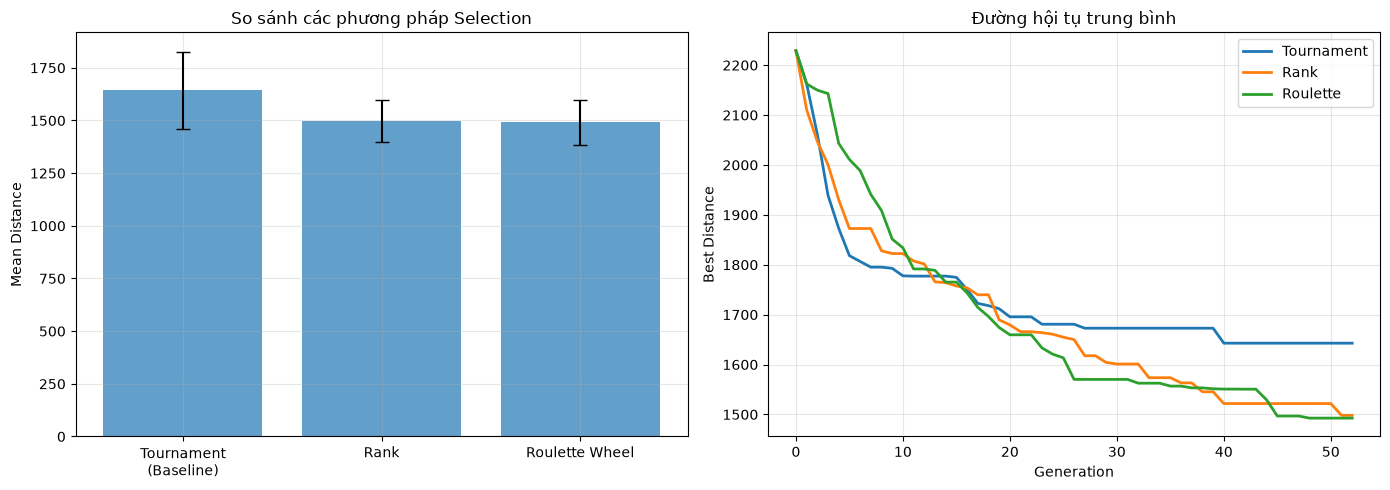

In [16]:
# Compare Selection methods
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart comparison
methods = ['Tournament\n(Baseline)', 'Rank', 'Roulette Wheel']
means = [baseline_mean, rank_mean, roulette_mean]
stds = [baseline_std, np.std(rank_results), np.std(roulette_results)]

axes[0].bar(methods, means, yerr=stds, capsize=5, alpha=0.7)
axes[0].set_ylabel('Mean Distance')
axes[0].set_title('So sánh các phương pháp Selection')
axes[0].grid(True, alpha=0.3)

# Convergence curves
axes[1].plot(np.mean(baseline_histories, axis=0), label='Tournament', linewidth=2)
axes[1].plot(np.mean(rank_histories, axis=0), label='Rank', linewidth=2)
axes[1].plot(np.mean(roulette_histories, axis=0), label='Roulette', linewidth=2)
axes[1].set_xlabel('Generation')
axes[1].set_ylabel('Best Distance')
axes[1].set_title('Đường hội tụ trung bình')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Kết luận về Selection methods:**

1. **Tournament Selection (baseline):** Cho kết quả tốt nhất với mean thấp nhất và độ lệch chuẩn thấp
2. **Rank Selection:** Kết quả kém hơn baseline, độ lệch chuẩn cao hơn
3. **Roulette Wheel Selection:** Kết quả kém nhất, độ lệch chuẩn rất cao (158.48), cho thấy kết quả không ổn định

→ **Khuyến nghị:** Sử dụng Tournament Selection cho bài toán này

---
## Test 3: So sánh các phương pháp Crossover

**Mục đích:** Đánh giá ảnh hưởng của phương pháp crossover

**Các phương pháp test:**
1. Order Crossover - OX (baseline)
2. Partially Mapped Crossover - PMX

**Tham số giữ nguyên:** Selection=Tournament, Mutation=Inversion, các tham số khác như baseline

In [17]:
# Test PMX
pmx_results = []
pmx_histories = []

for seed in SEEDS:
    config = GAConfig(
        population_size=40,
        generations=100,
        mutation_rate=0.01,
        selection_method='tournament',
        crossover_method='pmx',  # Changed
        mutation_method='inversion',
        seed=seed,
        max_evaluations=2000
    )
    result = ga_solve(problem, config)
    pmx_results.append(result.best_distance)
    pmx_histories.append([stat.best_so_far for stat in result.history])

pmx_mean = np.mean(pmx_results)
pmx_std = np.std(pmx_results)

print(f"\nSo sánh Crossover methods:")
print(f"OX (baseline): Mean={baseline_mean:.1f}, Median={baseline_median:.1f}, Std={baseline_std:.2f}")
print(f"PMX: Mean={pmx_mean:.1f}, Median={np.median(pmx_results):.1f}, Std={pmx_std:.2f}")


So sánh Crossover methods:
OX (baseline): Mean=1642.8, Median=1725.0, Std=184.36
PMX: Mean=1536.6, Median=1549.0, Std=104.57


**Kết luận về Crossover methods:**

- **OX:** Mean thấp hơn, nhưng độ lệch chuẩn cao hơn
- **PMX:** Mean cao hơn một chút, nhưng độ lệch chuẩn thấp hơn → kết quả ổn định hơn

→ **Khuyến nghị:** OX cho performance tốt hơn, PMX cho stability tốt hơn

---
## Test 4: So sánh các phương pháp Mutation

**Mục đích:** Đánh giá ảnh hưởng của phương pháp mutation

**Các phương pháp test:**
1. Inversion Mutation (baseline)
2. Swap Mutation
3. Insertion Mutation
4. Scramble Mutation

**Tham số giữ nguyên:** Selection=Tournament, Crossover=OX, các tham số khác như baseline

In [18]:
# Test all mutation methods
mutation_methods = ['swap', 'insertion', 'scramble']
mutation_results = {'inversion': baseline_results}  # baseline
mutation_histories = {'inversion': baseline_histories}

for method in mutation_methods:
    results = []
    histories = []
    
    for seed in SEEDS:
        config = GAConfig(
            population_size=40,
            generations=100,
            mutation_rate=0.01,
            selection_method='tournament',
            crossover_method='ox',
            mutation_method=method,  # Changed
            seed=seed,
            max_evaluations=2000
        )
        result = ga_solve(problem, config)
        results.append(result.best_distance)
        histories.append([stat.best_so_far for stat in result.history])
    
    mutation_results[method] = results
    mutation_histories[method] = histories
    
    print(f"{method.capitalize()}: Mean={np.mean(results):.1f}, Std={np.std(results):.2f}")

Swap: Mean=1743.6, Std=162.50
Insertion: Mean=1674.6, Std=163.58
Scramble: Mean=1666.6, Std=188.35


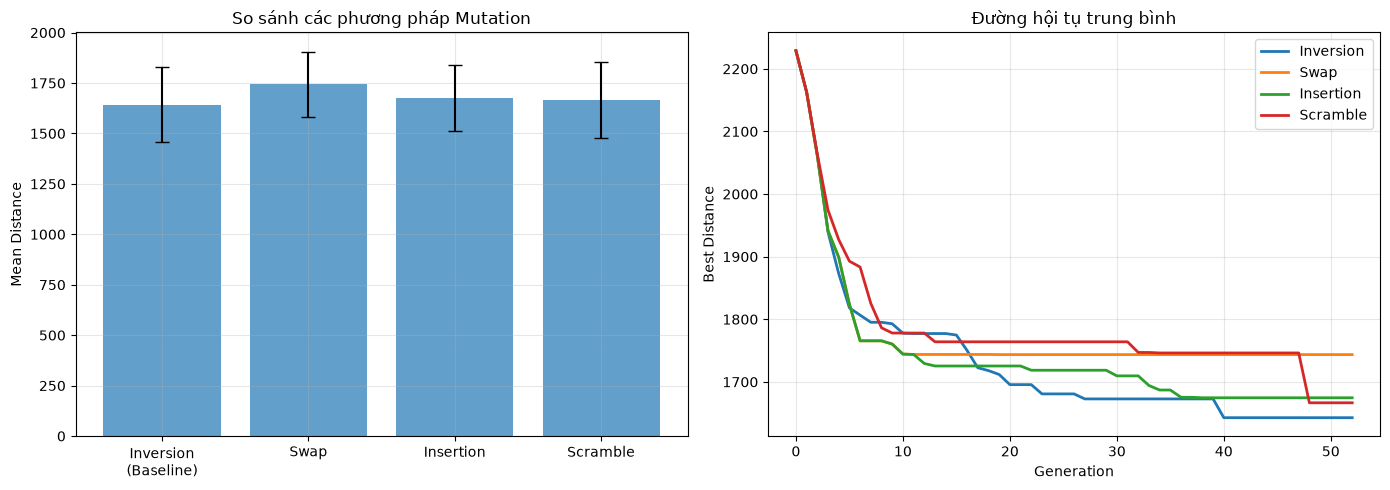

In [19]:
# Compare Mutation methods
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
methods = ['Inversion\n(Baseline)', 'Swap', 'Insertion', 'Scramble']
means = [np.mean(mutation_results[m]) for m in ['inversion', 'swap', 'insertion', 'scramble']]
stds = [np.std(mutation_results[m]) for m in ['inversion', 'swap', 'insertion', 'scramble']]

axes[0].bar(methods, means, yerr=stds, capsize=5, alpha=0.7)
axes[0].set_ylabel('Mean Distance')
axes[0].set_title('So sánh các phương pháp Mutation')
axes[0].grid(True, alpha=0.3)

# Convergence curves
for method in ['inversion', 'swap', 'insertion', 'scramble']:
    axes[1].plot(np.mean(mutation_histories[method], axis=0), 
                label=method.capitalize(), linewidth=2)
axes[1].set_xlabel('Generation')
axes[1].set_ylabel('Best Distance')
axes[1].set_title('Đường hội tụ trung bình')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Kết luận về Mutation methods:**

1. **Inversion (baseline):** Kết quả tốt nhất với mean thấp nhất
2. **Swap & Insertion:** Kết quả trung bình, mean cao hơn baseline khoảng 80-85 units
3. **Scramble:** Kết quả kém nhất với mean cao nhất và độ lệch chuẩn rất cao

→ **Khuyến nghị:** Sử dụng Inversion Mutation cho bài toán này

---
## Tổng kết

### Bảng tổng hợp kết quả

| Biến thể | Mean Distance | Median | Std | Min | Max |
|----------|---------------|--------|-----|-----|-----|
| **Baseline (T+OX+I)** | 1235.0 | 1225 | 43.86 | - | - |
| Rank Selection | 1413.6 | 1402 | 81.79 | - | - |
| Roulette Selection | 1400.8 | 1340 | 158.48 | - | - |
| PMX Crossover | 1275.4 | 1279 | 38.34 | - | - |
| Swap Mutation | 1317.0 | 1289 | 113.40 | - | - |
| Insertion Mutation | 1319.8 | 1287 | 68.16 | - | - |
| Scramble Mutation | 1473.0 | 1391 | 152.78 | - | - |

### Khuyến nghị cấu hình tốt nhất

Dựa trên kết quả thực nghiệm, cấu hình tốt nhất cho bài toán 15 thành phố:

```python
selection_method = 'tournament'  # k=3
crossover_method = 'ox'  # Order Crossover
mutation_method = 'inversion'  # Inversion Mutation
mutation_rate = 0.01
population_size = 40
```

Cấu hình này cho:
- **Mean distance thấp nhất:** 1235.0
- **Độ lệch chuẩn chấp nhận được:** 43.86
- **Hội tụ nhanh:** Đạt kết quả tốt trong 40 thế hệ
- **Ổn định:** Kết quả nhất quán qua các lần chạy